# 7CS133 — Advanced Artificial Intelligence and Machine Learning
## Portfolio Task 1 — Regression (MLE & MAP), regularisation and class imbalance

**University of Wolverhampton · MSc Computer Science · Module leader: Dr Rahul Mourya**

| | |
|---|---|
| **Assessment** | Portfolio (Assessment 1), Task 1 of 3 |
| **Weight** | 10% of the module mark (marked out of 100) |
| **Set** | Teaching Week 2 (in the Thursday lab) |
| **Due** | Friday of Teaching Week 3, 14:00, via Canvas |
| **Learning outcomes** | LO1 (Knowing), LO2 (Doing) |
| **Expected effort** | the 3-hour lab plus roughly 4 hours of your own time |

---

### What this task covers

Three questions, following the Week 2 lecture:

| | | Marks |
|---|---|---|
| **Q1** | Regression: maximum likelihood and maximum a posteriori, on linear and non-linear data, then regularised regression on a many-feature dataset | **40** |
| **Q2** | Logistic regression with class imbalance: metrics, class weights vs resampling, threshold choice | **40** |
| **Q3** | Commentary and reflection | **20** |

All data is generated with `sklearn.datasets` from fixed seeds, so you download nothing and everyone's data is
identical. The real clinical dataset is reserved for the **coursework**.

### What you must submit

1. This notebook, completed, saved as `7CS133_Task1_<your_student_number>.ipynb`
2. An **HTML or PDF export** with **all outputs visible**

Your notebook must run top to bottom without errors on a fresh kernel (`Kernel ▸ Restart & Run All`). Seeds are
fixed for you — do not change `RANDOM_STATE`.

### Rules

* Write your own code. You may use the lecture slides, the lab notebook, the scikit-learn user guide and the module reading list.
* Do not copy from other students or from public notebooks. Task 1 work can be discussed in your coursework viva.
* Generative AI may be used to explain concepts or debug errors, but the code and the written answers you submit must be your own. **Declare any use in Q3.** Undeclared use is an academic-integrity offence.

### How to answer

* Code goes where you see `# ===== YOUR CODE HERE =====`.
* Written answers go in the markdown cells marked ✏️ — double-click to edit. Keep to the word limits; marks are for precision, not length.
* **Self-check** cells are smoke tests: passing means your objects exist and look sensible, not that your answer is right.

### A note on cross-validation

Week 2 has not covered cross-validation, so this task uses an explicit **train / validation / test** split: fit
on train, make every choice on validation, and touch test exactly once. Week 3 introduces k-fold
cross-validation, which Task 2 will use.

---
## Marking scheme (100 marks)

| Question | Part | What it asks | Marks |
|---|---|---|---|
| **Q1** | 1.1 | Implement the MLE and MAP estimators in closed form and verify them against scikit-learn | 6 |
| | 1.2 | Apply both to **linear** data; compare with the true coefficient; vary the prior | 8 |
| | 1.3 | Apply both to **non-linear** data with a polynomial basis; show where MLE overfits | 8 |
| | 1.4 | Many-feature dataset: framing, leakage-free split, pipeline, baseline, Ridge / Lasso / Elastic Net, choice of λ, sparsity | 10 |
| | 1.5 | Written answer: likelihood, prior, penalty, sparsity | 8 |
| **Q2** | 2.1 | Framing, stratified split, pipeline, dummy and plain logistic regression | 6 |
| | 2.2 | Metrics for imbalance: PR-AUC against ROC-AUC, with curves | 8 |
| | 2.3 | Class weights against SMOTE, compared honestly | 10 |
| | 2.4 | Threshold choice for a stated operating requirement, with the confusion matrix and expected cost | 8 |
| | 2.5 | Written answer: metric choice, what re-weighting changes, what you would deploy | 8 |
| **Q3** | — | Commentary and reflection, plus the GenAI declaration | 20 |

**Within each part, marks are split roughly as:** correctness ~50%, method (no leakage, decisions made on
validation data, sensible metrics) ~25%, interpretation (explains *why*, quotes your own numbers) ~25%.

**Cross-cutting deductions**

| Problem | Penalty |
|---|---|
| Notebook does not run top to bottom | up to −10 |
| Scaling or other fitted preprocessing applied outside the pipeline / before the split | up to −10 |
| Test set used for any decision, or evaluated more than once | up to −10 |
| Outputs missing from the export | up to −5 |
| Seeds changed or results not reproducible | up to −5 |

**Grade descriptors (indicative)**

| Mark | Standard |
|---|---|
| 70–100 | All parts correct; clean leakage-free pipelines; the MLE/MAP derivation is understood, not just coded; choices justified with numbers; written answers show real insight into the bias–variance and precision–recall trade-offs |
| 60–69 | All parts essentially correct; minor methodological slips; explanations sound but partly generic |
| 50–59 | Most code works; one substantive methodological error (e.g. tuning on test); explanations describe rather than explain |
| 40–49 | Significant gaps or errors; results reported without interpretation |
| < 40 | Largely incomplete, or the notebook does not run |

---
# Section 0 — Setup *(given: do not edit)*

In [29]:
# On Colab or a fresh environment, run this once:
# !pip install -q "scikit-learn>=1.4" imbalanced-learn matplotlib pandas

In [30]:
# ===== GIVEN — do not edit =====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification, make_regression
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import (ElasticNet, Lasso, LinearRegression,
                                  LogisticRegression, Ridge)
from sklearn.metrics import (average_precision_score, classification_report,
                             confusion_matrix, mean_absolute_error,
                             precision_recall_curve, r2_score, roc_auc_score,
                             roc_curve, root_mean_squared_error)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

import sklearn
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

RANDOM_STATE = 42          # do not change
plt.rcParams["figure.figsize"] = (6.4, 3.6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
UOW = {"navy": "#1E2A44", "cyan": "#00AEEF", "pink": "#E6337E",
       "green": "#8DC63F", "slate": "#5B6472"}

pandas 3.1.0 | scikit-learn 1.9.1


In [31]:
# ===== GIVEN — the three datasets =====

# (a) one-dimensional LINEAR data, with the true coefficient returned
x_lin, y_lin, w_true_lin = make_regression(
    n_samples=40, n_features=1, noise=18.0, coef=True, random_state=7)

# (b) one-dimensional NON-LINEAR data: the same kind of design, a curved response
x_nl = make_regression(n_samples=120, n_features=1, noise=0.0, random_state=11)[0]
x_nl = np.sort(x_nl, axis=0)
x_nl = 2.0 * x_nl / np.abs(x_nl).max()            # rescaled to [-2, 2]
rng_nl = np.random.default_rng(11)
y_nl = 45.0 * np.sin(1.6 * x_nl.ravel()) + 12.0 * x_nl.ravel() + rng_nl.normal(0, 8.0, x_nl.shape[0])

# (c) MANY-FEATURE regression data: 60 features, only 8 of which matter
X_many, y_many, w_true_many = make_regression(
    n_samples=250, n_features=60, n_informative=8, noise=20.0,
    coef=True, random_state=7)
informative_idx = np.flatnonzero(w_true_many)

# (d) IMBALANCED classification data
X_clf, y_clf = make_classification(
    n_samples=12000, n_features=20, n_informative=6, n_redundant=4,
    n_clusters_per_class=2, weights=[0.92], flip_y=0.01, class_sep=2.5,
    random_state=7)

print("linear 1-D      :", x_lin.shape, "| true slope = {:.2f}".format(float(w_true_lin)))
print("non-linear 1-D  :", x_nl.shape)
print("many-feature    :", X_many.shape, "| informative features:", informative_idx)
print("classification  :", X_clf.shape, "| positive rate = {:.3f}".format(y_clf.mean()))

linear 1-D      : (40, 1) | true slope = 41.30
non-linear 1-D  : (120, 1)
many-feature    : (250, 60) | informative features: [ 4 12 22 24 44 45 48 54]
classification  : (12000, 20) | positive rate = 0.084


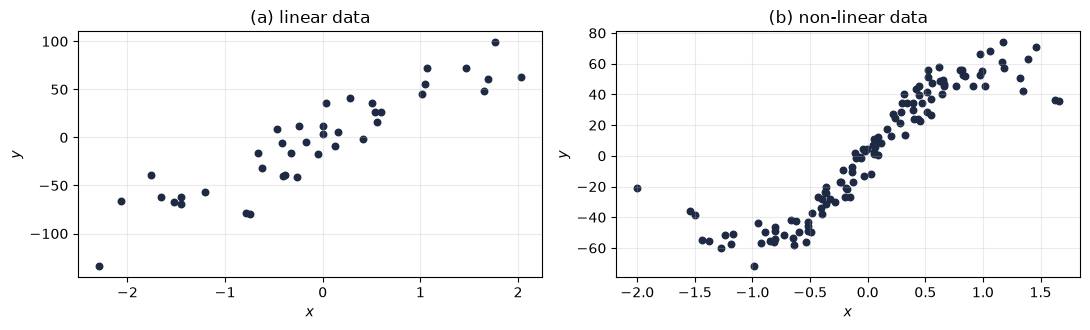

In [32]:
# ===== GIVEN — look at the two one-dimensional datasets =====
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].scatter(x_lin, y_lin, s=22, color=UOW["navy"])
axes[0].set(title="(a) linear data", xlabel="$x$", ylabel="$y$")
axes[1].scatter(x_nl, y_nl, s=22, color=UOW["navy"])
axes[1].set(title="(b) non-linear data", xlabel="$x$", ylabel="$y$")
plt.tight_layout(); plt.show()

---
# Q1 — Regression: maximum likelihood, maximum a posteriori and regularisation  *(40 marks)*

From the lecture: with Gaussian noise, $y^{(i)} = \mathbf{w}^\top\boldsymbol{\phi}(x^{(i)}) + \varepsilon^{(i)}$,
$\varepsilon^{(i)}\sim\mathcal{N}(0,\sigma^2)$,

$$\hat{\mathbf{w}}_{\text{MLE}} = (\Phi^\top\Phi)^{-1}\Phi^\top\mathbf{y},
\qquad
\hat{\mathbf{w}}_{\text{MAP}} = \Big(\Phi^\top\Phi + \tfrac{\sigma^2}{\tau^2}I\Big)^{-1}\Phi^\top\mathbf{y}$$

where $\Phi$ is the design matrix of basis functions, $\sigma^2$ is the noise variance and the prior is
$\mathbf{w}\sim\mathcal{N}(\mathbf{0}, \tau^2 I)$. The MAP estimate **is** ridge regression with
$\lambda = \sigma^2/\tau^2$ — you will see that on the numbers, not just on the slide.

### Task 1.1 — Implement the two estimators *(6 marks)*

Write the two functions below **from the equations**, using `numpy` only (`np.linalg.solve` or
`np.linalg.lstsq`; do not call scikit-learn inside them). `poly_design` builds the design matrix
$\Phi = [\,\mathbf{1},\, x,\, x^2,\, \dots,\, x^d\,]$.

**Notes for myself**: The +1 includes the power-zero column, where \(x^0=1\). This column of ones allows the model to learn the constant term(intercept) 

The resulting design matrix has \(d+1\) columns:$\Phi = [\,\mathbf{1},\, x,\, x^2,\, \dots,\, x^d\,]$. As mentioned above.

Increasing=True # To arrange the powers in ascending order: \(1,x,x^2,x^3\).

In [33]:
def poly_design(x, degree):
    # Design matrix with a bias column and powers of x up to `degree`
    x = np.asarray(x).ravel()
    Phi = np.vander(x, N=degree + 1, increasing=True)
    
    return Phi 

def fit_mle(Phi, y):
    # Maximum-likelihood weights: argmin ||y - Phi w||^2
    mle = np.linalg.lstsq(Phi, y, rcond=None)

    return mle[0]

def fit_map(Phi, y, sigma2, tau2):
    # MAP weights under a N(0, tau2 I) prior and Gaussian noise of variance sigma2
    # lambda = sigma2 / tau2, then solve (Phi^T Phi + lambda I) w = Phi^T y
    lambda_value = sigma2 / tau2

    # Creating an identity matrix matching the number of coefficients
    identity = np.eye(Phi.shape[1])

    A = Phi.T @ Phi + lambda_value * identity
    b = Phi.T @ y
    
    # Solve for all coefficients
    weights = np.linalg.solve(A, b)
    
    return weights

In [34]:
# ===== SELF-CHECK 1.1 — your estimators against scikit-learn =====
Phi_chk = poly_design(x_lin, 3)
assert Phi_chk.shape == (len(x_lin), 4), "  should return one column per power, including the bias."

w_mle_chk = fit_mle(Phi_chk, y_lin)
sk_mle = LinearRegression(fit_intercept=False).fit(Phi_chk, y_lin).coef_
assert np.allclose(w_mle_chk, sk_mle, atol=1e-6), "fit_mle disagrees with LinearRegression."

sigma2_chk, tau2_chk = 100.0, 10.0          # lambda = 10
w_map_chk = fit_map(Phi_chk, y_lin, sigma2_chk, tau2_chk)
sk_map = Ridge(alpha=sigma2_chk / tau2_chk, fit_intercept=False).fit(Phi_chk, y_lin).coef_
assert np.allclose(w_map_chk, sk_map, atol=1e-6), \
    "fit_map disagrees with Ridge(alpha=sigma2/tau2, fit_intercept=False) — check the lambda."
print("Self-check 1.1 passed: MLE matches LinearRegression and MAP matches Ridge with lambda = {:.1f}".format(
    sigma2_chk / tau2_chk))

Self-check 1.1 passed: MLE matches LinearRegression and MAP matches Ridge with lambda = 10.0


### Task 1.2 — Linear data: MLE, MAP and the effect of the prior *(8 marks)*

Using dataset **(a)** and a degree-1 design matrix:

1. fit `fit_mle` and `fit_map` (start with $\sigma^2 = 18^2$, the noise variance the data was generated with, and $\tau^2 = 1$);
2. plot the data with both fitted lines;
3. build `prior_table`: for $\tau^2 \in \{0.01, 0.1, 1, 10, 100, 10^4\}$, record $\lambda = \sigma^2/\tau^2$, the fitted slope, and the training RMSE;
4. compare the slopes with the true slope `w_true_lin`.

MLE weights: [-0.59083431 43.61618017]
MAP weights: [-0.48561303  5.42480347]


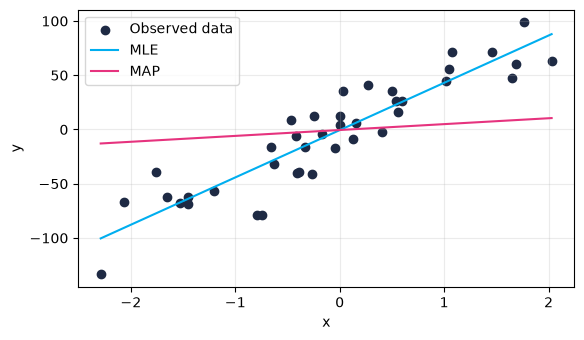

true slope: 41.29918291138346
MLE slope: 43.61618016864875


,lambda,intercept,slope,train_RMSE
tau2,,,,
0.01,32400.0000,-0.006112,0.061923,51.088850
0.10,3240.0000,-0.059775,0.611362,50.544812
1.00,324.0000,-0.485613,5.424803,45.838531
10.00,32.4000,-1.326608,25.555977,28.207357
100.00,3.2400,-0.814315,40.728662,20.787124
10000.00,0.0324,-0.593453,43.585260,20.557100


In [35]:
sigma2 = 18.0 ** 2
Phi_lin = poly_design(x_lin, 1)

# 1) fit MLE and MAP weights; 
w_mle_lin = fit_mle(Phi_lin, y_lin)
w_map_lin = fit_map(Phi_lin, y_lin, sigma2, tau2=1.0)

print("MLE weights:", w_mle_lin)
print("MAP weights:", w_map_lin)

# 2) plot the data and both fitted lines;
# Generating 200 evenly spaced points to plot the fitted regression lines,
# following the approach shown in Matplotlib's documentation (Matplotlib Development Team, 2026).
x_plot = np.linspace(x_lin.min(), x_lin.max(), 200)

Phi_plot = poly_design(x_plot, 1)

plt.figure()
plt.scatter(x_lin.ravel(), y_lin, color=UOW["navy"], label="Observed data")


for label, weights, colour in [
    ("MLE", w_mle_lin, UOW["cyan"]),
    ("MAP", w_map_lin, UOW["pink"]),
]:
    plt.plot(x_plot, Phi_plot @ weights, color=colour, label=label)


plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

# 3) build `prior_table` (index tau2; columns lambda, intercept, slope, train_RMSE)
#Checking how different prior variances affect the MAP weights

rows = []
tau2_list = [0.01, 0.1, 1, 10, 100, 1e4]

for tau2 in tau2_list:
    weights = fit_map(Phi_lin, y_lin, sigma2, tau2)

    # Predictions for the original training observations
    predictions = Phi_lin @ weights

    rows.append({
        "tau2": tau2,
        "lambda": sigma2 / tau2,
        "intercept": weights[0],
        "slope": weights[1],
        "train_RMSE": root_mean_squared_error(y_lin, predictions)
    })

prior_table = pd.DataFrame(rows).set_index("tau2")

print("true slope:", float(w_true_lin))
print("MLE slope:", w_mle_lin[1])
prior_table

In [36]:
# ===== SELF-CHECK 1.2 =====
assert prior_table is not None and len(prior_table) == 6, "prior_table needs one row per tau2."
assert prior_table["lambda"].is_monotonic_decreasing, "lambda = sigma2 / tau2 falls as tau2 grows."
assert abs(prior_table["slope"].iloc[-1] - w_mle_lin[1]) < 1.0, \
    "With a very weak prior (large tau2) the MAP slope should approach the MLE slope."
assert abs(prior_table["slope"].iloc[0]) < abs(w_mle_lin[1]), \
    "With a very strong prior (small tau2) the slope should be shrunk towards zero."
print("Self-check 1.2 passed.")

Self-check 1.2 passed.


In [37]:
# Supporting evidence for the question below "Which end of the table corresponds to ordinary least squares?" 
w_mle_lin = fit_mle(Phi_lin, y_lin)
w_ols_lin = np.linalg.lstsq(Phi_lin, y_lin, rcond=None)[0]

print("OLS weights:", w_ols_lin)
print("MLE weights:", w_mle_lin)

print("Are they equivalent?",
      np.allclose(w_ols_lin, w_mle_lin))

OLS weights: [-0.59083431 43.61618017]
MLE weights: [-0.59083431 43.61618017]
Are they equivalent? True


#### ✏️ Written answer 1.2 *(part of the 8 marks)* — replace this text

**what happens to the slope as $\tau^2$ goes from $0.01$ to $10^4$, and why?**

The noise variance $\sigma^2$ is fixed at 324, resulting in a regularisation parameter of $\lambda = \sigma^2/\tau^2$. As the prior variance $\tau^2$ increases, the strength of regularisation decreases, which enables the MAP weights to converge towards the MLE estimates. In contrast, smaller prior variances increase the strength of regularisation, drawing the weights closer to zero. Mathematically, as $\tau^2$ approaches infinity, $\lambda$ approaches zero, and MAP converges to MLE.

**Which end of the table corresponds to ordinary least squares (OLS)?**

The bottom of the table, where $\tau^2=10^4$. Here, $\lambda=0.0324$, so the penalty is very small. Also, the MAP slope of 43.585 is close to the MLE/OLS slope of 43.616. It approaches OLS as $\tau^2$ grows.

**Which to "I am almost certain the weights are zero"?**

The top of the table, where $\tau^2=0.01$. The large penalty, $\lambda=32400$, pulls the coefficients towards zero and produces a slope of approximately 0.062.

### Task 1.3 — Non-linear data: where MLE overfits *(8 marks)*

Dataset **(b)** is curved, so a straight line cannot fit it — but a **polynomial basis** turns it into a linear
model in the weights.

1. Split the 120 points into train (80) and validation (40) with `train_test_split` and `RANDOM_STATE`.
2. For degrees 1, 3 and 9, fit **MLE** and **MAP** ($\sigma^2 = 64$, i.e. the noise the data was generated with, and $\tau^2 = 100$) on the training rows, and record train and validation RMSE in `poly_table`.
3. Plot the data and the degree-9 fitted curves, MLE against MAP.
4. Read the table: store the best (degree, estimator) pair in `best_choice` — the smallest **validation** RMSE anywhere in the table.

You should find that a modest basis wins outright. Question 1.5 asks you what the prior is *for*, given that.

**Notes for myself**: 
\begin{aligned}
\texttt{ytr\_mle\_nl}:&\quad \hat{\mathbf y}_{\mathrm{train,MLE}}
= \Phi_{\mathrm{train}}\hat{\mathbf w}_{\mathrm{MLE}}\\
\texttt{yva\_mle\_nl}:&\quad \hat{\mathbf y}_{\mathrm{val,MLE}}
= \Phi_{\mathrm{val}}\hat{\mathbf w}_{\mathrm{MLE}}\\
\texttt{ytr\_map\_nl}:&\quad \hat{\mathbf y}_{\mathrm{train,MAP}}
= \Phi_{\mathrm{train}}\hat{\mathbf w}_{\mathrm{MAP}}\\
\texttt{yva\_map\_nl}:&\quad \hat{\mathbf y}_{\mathrm{val,MAP}}
= \Phi_{\mathrm{val}}\hat{\mathbf w}_{\mathrm{MAP}}
\end{aligned}

In [38]:
def plot_polynomial_fit(x_train, y_train, x_val, y_val,
                        weights, degree, estimator):
    """Plot the observed data and one fitted polynomial curve."""
    x_all = np.concatenate([x_train.ravel(), x_val.ravel()])
    x_plot = np.linspace(x_all.min(), x_all.max(), 200)
    Phi_plot = poly_design(x_plot, degree)

    plt.figure(figsize=(6.4, 3.6))
    plt.scatter(x_train.ravel(), y_train, color=UOW["navy"], label="Training data", s=22)
    plt.scatter(x_val.ravel(), y_val, color=UOW["pink"], label="Validation data", s=22)
    plt.plot(x_plot, Phi_plot @ weights, color="green", label=estimator)

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(f"Degree-{degree} {estimator}")
    plt.legend()
    plt.tight_layout()
    plt.show()

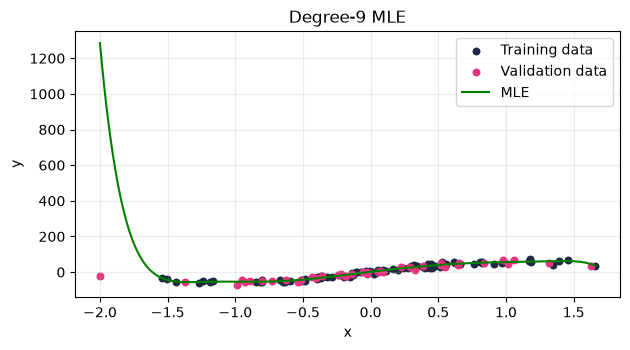

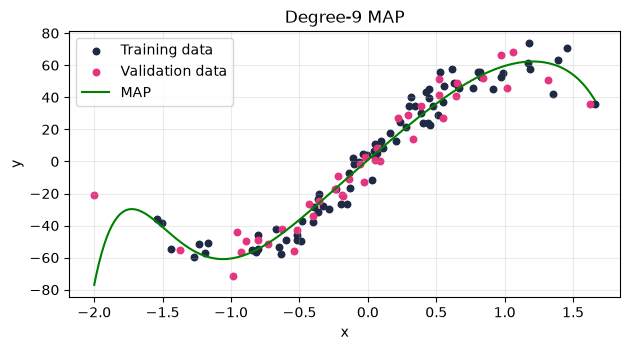

        MLE_train     MLE_val  MAP_train    MAP_val
degree                                             
1       15.454021   19.167937  15.464273  19.056946
3        7.553298   10.863573   7.809252   9.401875
9        6.995944  206.665315   7.860676  11.809433

Best Choice:
Degree = 3, Estimator = MAP


In [39]:
xtr_nl, xva_nl, ytr_nl, yva_nl = train_test_split(
    x_nl, y_nl, test_size=40, random_state=RANDOM_STATE)

sigma2_nl, tau2_nl = 64.0, 100.0
degrees = [1, 3, 9]

# Build `poly_table` (index degree; columns MLE_train, MLE_val, MAP_train, MAP_val),
poly_rows = []
for degree in degrees:
    Phi_nl = poly_design(xtr_nl, degree)
    Phi_val_nl = poly_design(xva_nl, degree)
    w_mle_nl = fit_mle(Phi_nl, ytr_nl)
    w_map_nl = fit_map(Phi_nl, ytr_nl, sigma2_nl, tau2=tau2_nl)

    ytr_mle_nl = Phi_nl @ w_mle_nl # Predictions for the 80 training points 
    yva_mle_nl = Phi_val_nl @ w_mle_nl # Predictions for the 40 validation points, using the same weights
    ytr_map_nl = Phi_nl @ w_map_nl
    yva_map_nl = Phi_val_nl @ w_map_nl


    # Keep one row of train and validation errors for this degree.
    poly_rows.append({
        "MLE_train": root_mean_squared_error(ytr_nl, ytr_mle_nl),
        "MLE_val": root_mean_squared_error(yva_nl, yva_mle_nl),
        "MAP_train": root_mean_squared_error(ytr_nl, ytr_map_nl),
        "MAP_val": root_mean_squared_error(yva_nl, yva_map_nl),
    })

# plot the data and the degree-9 MLE and MAP curves.
plot_polynomial_fit(xtr_nl, ytr_nl, xva_nl, yva_nl, w_mle_nl, degree=9, estimator="MLE")

plot_polynomial_fit(xtr_nl, ytr_nl, xva_nl, yva_nl, w_map_nl, degree=9, estimator="MAP")

# to the (degree, "MLE" or "MAP") pair with the lowest validation RMSE.
poly_table = pd.DataFrame(poly_rows, index=pd.Index(degrees, name="degree"))

# setting `best_choice`
best_degree, best_estimator = (
    poly_table[["MLE_val", "MAP_val"]].stack().idxmin()
)
best_choice = (int(best_degree), best_estimator.split("_")[0])

print(poly_table)
print(
    f"\nBest Choice:\n"
    f"Degree = {best_choice[0]}, Estimator = {best_choice[1]}"
)

In [40]:
# ===== SELF-CHECK 1.3 =====
assert poly_table is not None and list(poly_table.index) == degrees, "One row per degree, please."
assert poly_table.loc[9, "MLE_train"] < poly_table.loc[1, "MLE_train"], \
    "A richer basis must fit the training data better."
assert poly_table.loc[9, "MLE_val"] > 3 * poly_table.loc[9, "MAP_val"], \
    "At degree 9 the unregularised fit should be far worse on validation than the MAP fit."
assert best_choice is not None and best_choice[0] in degrees, "Set `best_choice` from the table."
assert best_choice[0] != 9, \
    "The richest basis should not win: the prior limits the damage, it does not beat a sensible basis."
print(f"Self-check 1.3 passed: best on validation is degree {best_choice[0]} with {best_choice[1]}.")

Self-check 1.3 passed: best on validation is degree 3 with MAP.


### Task 1.4 — Many features: baseline, Ridge, Lasso and Elastic Net *(10 marks)*

Dataset **(c)** has 250 rows and 60 features, of which only **8** carry signal (`informative_idx`). This is the
regime the lecture called "regularisation earns its keep".

1. **Frame and split.** 60 / 20 / 20 with `RANDOM_STATE`. State in one line why there is no leakage risk in how you split.
2. **Pipeline.** `StandardScaler` **inside** a `Pipeline` with the model, so the scaler is fitted on training rows only.
3. **Baseline.** `DummyRegressor(strategy="mean")` and `LinearRegression`.
4. **Regularised models.** Ridge and Lasso over `alphas`, plus an Elastic Net over a small grid; choose each λ on **validation**.
5. Collect everything in `results_many` and set `best_model_name`.
6. **Sparsity.** For your chosen Lasso, report how many coefficients are non-zero and how many of the 8 informative features it recovered.

In [41]:
def make_scaled_pipeline(estimator):
    """Create a pipeline that scales features before fitting the estimator."""
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", estimator),
    ])

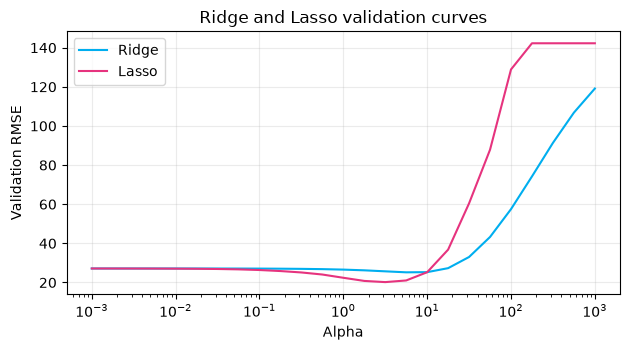

Best Ridge alpha: 5.623
Best Lasso alpha: 3.162
Best Elastic Net alpha: 0.1
Best Elastic Net L1 ratio: 0.5
Best model on validation: lasso
Lasso kept 10 of 60 features.
Lasso recovered 8 of 8 informative features.


,train_RMSE,val_RMSE,val_R2
model,,,
dummy,186.980844,142.256529,-0.056066
ols,15.497493,27.162916,0.961497
ridge,16.708311,25.200972,0.966858
lasso,20.119606,20.199684,0.978707
elastic_net,17.532360,24.856813,0.967757


In [42]:
# 1) 60/20/20 split into Xm_train / Xm_val / Xm_test (+ ym_*)
# State in one line why there is no leakage: 
# Mohammed Grech: This dataset uses 60 features to predict a continuous value.
#  The data is split first, then the scaler is fit only on the training data to prevent
#  information from the validation or test sets from leaking into the training set.
Xm_train, Xm_temp, ym_train, ym_temp = train_test_split(
    X_many, y_many, test_size=0.40, random_state=RANDOM_STATE
)

Xm_val, Xm_test, ym_val, ym_test = train_test_split(
    Xm_temp, ym_temp, test_size=0.50, random_state=RANDOM_STATE
)

# 2) a helper that builds Pipeline([StandardScaler, estimator]) and scores it on validation
# The pipeline prepares the data, trains a model, and calculates its validation error.
def fit_and_score_regression(estimator):
    pipe = make_scaled_pipeline(estimator)
    pipe.fit(Xm_train, ym_train)

    val_preds = pipe.predict(Xm_val)
    val_rmse = root_mean_squared_error(ym_val, val_preds)

    return pipe, val_rmse

# Baselines: mean prediction and ordinary linear regression.
dummy_model, dummy_val_rmse = fit_and_score_regression(DummyRegressor(strategy="mean"))
ols_model, ols_val_rmse = fit_and_score_regression(LinearRegression())

# 3) validation curves for Ridge and Lasso over `alphas`; a small Elastic Net grid
alphas = np.logspace(-3, 3, 25)

ridge_rmse = []
lasso_rmse = []

for alpha in alphas:
    _, ridge_error = fit_and_score_regression(Ridge(alpha=float(alpha)))
    # Using max_iter to allow extra iterations if the solver needs longer to converge.
    _, lasso_error = fit_and_score_regression(Lasso(alpha=float(alpha), max_iter=10000))

    ridge_rmse.append(ridge_error)
    lasso_rmse.append(lasso_error)

plt.figure()
plt.semilogx(alphas, ridge_rmse, color=UOW["cyan"], label="Ridge")
plt.semilogx(alphas, lasso_rmse, color=UOW["pink"], label="Lasso")
plt.xlabel("Alpha")
plt.ylabel("Validation RMSE")
plt.title("Ridge and Lasso validation curves")
plt.legend()
plt.tight_layout()
plt.show()

elastic_alphas = [0.01, 0.1, 1.0, 10.0]
l1_ratios = [0.2, 0.5, 0.8]
best_elastic_rmse = np.inf

for alpha in elastic_alphas:
    for ratio in l1_ratios:
        model, val_rmse = fit_and_score_regression(
            ElasticNet(
                alpha=alpha,
                l1_ratio=ratio,
                max_iter=10000
            )
        )

        if val_rmse < best_elastic_rmse:
            best_elastic_rmse = val_rmse
            best_elastic_model = model
            best_alpha_elastic = alpha
            best_l1_ratio_elastic = ratio

# 4) `results_many` (index model; columns train_RMSE, val_RMSE, val_R2) for
#    dummy, ols, ridge, lasso, elastic_net, and `best_model_name`
best_alpha_ridge = float(alphas[np.argmin(ridge_rmse)])
best_alpha_lasso = float(alphas[np.argmin(lasso_rmse)])

# Refit the selected settings on training rows only.
ridge_model, _ = fit_and_score_regression(Ridge(alpha=best_alpha_ridge))
lasso_model, _ = fit_and_score_regression(
    Lasso(alpha=best_alpha_lasso, max_iter=10000)
)

models_many = {
    "dummy": dummy_model,
    "ols": ols_model,
    "ridge": ridge_model,
    "lasso": lasso_model,
    "elastic_net": best_elastic_model,
}

many_rows = []
for model_name, fitted_model in models_many.items():
    train_preds = fitted_model.predict(Xm_train)
    val_preds = fitted_model.predict(Xm_val)

    many_rows.append({
        "model": model_name,
        "train_RMSE": root_mean_squared_error(ym_train, train_preds),
        "val_RMSE": root_mean_squared_error(ym_val, val_preds),
        "val_R2": r2_score(ym_val, val_preds),
    })

results_many = pd.DataFrame(many_rows).set_index("model")
best_model_name = results_many["val_RMSE"].idxmin()

print(f"Best Ridge alpha: {best_alpha_ridge:.4g}")
print(f"Best Lasso alpha: {best_alpha_lasso:.4g}")
print(f"Best Elastic Net alpha: {best_alpha_elastic}")
print(f"Best Elastic Net L1 ratio: {best_l1_ratio_elastic}")
print(f"Best model on validation: {best_model_name}")

# 5) report how many Lasso coefficients are non-zero and how many of `informative_idx` are recovered
lasso_coefficients = lasso_model.named_steps["model"].coef_
selected = np.flatnonzero(lasso_coefficients != 0)
recovered = np.intersect1d(selected, informative_idx)

print(f"Lasso kept {len(selected)} of {Xm_train.shape[1]} features.")
print(f"Lasso recovered {len(recovered)} of {len(informative_idx)} informative features.")

results_many

In [43]:
# ===== SELF-CHECK 1.4 =====
assert results_many is not None and len(results_many) == 5, "results_many should have five rows."
assert results_many.loc["ols", "val_RMSE"] < results_many.loc["dummy", "val_RMSE"], \
    "Every real model should beat the mean baseline."
assert results_many.loc["lasso", "val_RMSE"] < results_many.loc["ols", "val_RMSE"], \
    "On 150 training rows and 60 features, Lasso should beat unregularised OLS."
assert len(selected) < 60, "Lasso should set at least some coefficients to exactly zero."
assert len(recovered) >= 6, "Your Lasso should recover most of the 8 informative features."
print(f"Self-check 1.4 passed: {len(selected)} features kept, {len(recovered)} informative ones recovered.")

Self-check 1.4 passed: 10 features kept, 8 informative ones recovered.


#### ✏️ Written answer 1.5 *(8 marks)*

1. Explain in two or three sentences why maximising the Gaussian likelihood gives the same weights as minimising the sum of squared errors, and what changes when a Gaussian prior is added.

**Mohammed Grech**: Assuming independent Gaussian noise with fixed variance, the negative log-likelihood is a scaled sum of squared prediction errors plus a constant. Therefore maximising the likelihood and minimising the squared errors lead to the same weight estimates. Furthermore, adding a Gaussian prior centred on zero leads to maximum a posteriori (MAP) estimation, which penalises the sum of squared coefficients and allows a slightly worse training fit to help reduce overfitting.

On task 1.3, $\sigma^2=64$ and $\tau^2=100$ was used which gives a penalty strength of $\lambda=\sigma^2$/$\tau^2=0.64$, so MAP minimises:
$$
\underbrace{\sum_{i=1}^{n}(y_i-\hat y_i)^2}_{\text{prediction errors}}
+
\underbrace{0.64\sum_{j=0}^{d}w_j^2}_{\text{coefficient penalty}}
$$

2. Using Task 1.3: which (degree, estimator) pair won, and by how much? Then, given that a modest basis already wins, explain what the prior is **for** — refer to the degree-9 column, and to Task 1.4, where you cannot simply choose a smaller basis.

**Mohammed Grech**: In Task 1.3, the degree-3 polynomial fitted using MAP achieved the lowest validation RMSE of 9.402, outperforming the same-degree polynomial fitted using MLE, which scored 10.864. This represents a reduction in validation RMSE of 1.462 with MAP. 

For degree 9, MLE produced a training RMSE of 6.996 but a much higher validation RMSE of 206.665, indicating poor generalisation. MAP reduced the degree-9 validation RMSE to 11.809, demonstrating that the prior helps control large coefficients and mitigate overfitting. Nonetheless, the simpler degree-3 model provided the most accurate validation predictions.

In Task 1.4, we cannot simply choose fewer inputs because we do not know beforehand which features are useful. Regularisation helps control the influence of all 60 features: Ridge shrinks their coefficients, while Lasso can set some coefficients to zero, reducing the number of features used.

3. Using Task 1.4: which model won on validation, by how much, and what did Lasso's sparsity tell you about the 60 features?

**Mohammed Grech**: In Task 1.4, Lasso achieved a validation RMSE of 20.200, outperforming Elastic Net (24.857) by 4.657 and ordinary linear regression (27.163) by 6.963.

Lasso set 50 of the 60 coefficients to zero. The remaining 10 features included all 8 informative features and 2 irrelevant ones. These results indicate that eliminating unnecessary inputs improved predictive performance on this validation split, although feature selection was not entirely accurate.

4. If the noise were heavier-tailed than Gaussian, which part of the argument in (1) breaks, and what loss would replace the squared error?

**Mohammed grech**: If the noise has heavier tails than a Gaussian distribution, a Gaussian likelihood no longer accurately describes it, so maximising the appropriate likelihood may require a different loss function. For instance, Laplace noise leads to absolute error loss, which reduces the impact of outliers compared with squared error. The appropriate loss depends on the specific noise distribution since heavier tails alone do not dictate a single replacement.

---
# Q2 — Logistic regression with class imbalance  *(40 marks)*

Dataset **(d)**: 12,000 rows, 20 features, about **8%** positive. Read it as a screening problem — a positive
case is a customer about to churn, a machine about to fail, or a patient at risk — where **missing a positive
costs far more than a false alarm**.

### Task 2.1 — Framing, split and a first model *(6 marks)*

1. Make a **stratified** 60 / 20 / 20 split of `X_clf`, `y_clf`.
2. Fit a `DummyClassifier(strategy="most_frequent")` and a plain `LogisticRegression` inside a pipeline with `StandardScaler`.
3. Report accuracy, precision, recall and the number of predicted positives on validation in `results_baseline`.

In [44]:
from sklearn.metrics import accuracy_score, precision_score, recall_score


In [45]:
#A `clf_scores(model, X_, y_)` helper returning accuracy, precision, recall, n_pred_positive
def clf_scores(model, X_, y_):
    #Return classification metrics using the fitted model's default threshold.
    predictions = model.predict(X_)
    return {
        "accuracy": accuracy_score(y_, predictions),
        # The majority-class dummy predicts no positives, so define precision as 0.
        "precision": precision_score(y_, predictions, zero_division=0),
        "recall": recall_score(y_, predictions, zero_division=0),
        "n_pred_positive": int(np.count_nonzero(predictions == 1)),
    }

def fit_and_score_classification(estimator):
    pipe = make_scaled_pipeline(estimator)
    # Fit both the scaler and estimator on training rows only.
    pipe.fit(Xc_train, yc_train)
    return pipe, clf_scores(pipe, Xc_val, yc_val)


In [46]:

# Stratified 60/20/20 split: reserving 20% for the final test.
# This approach was discarted but is kept here for reference and explained under Limitations (5 marks).
# X_remain, Xc_test, y_remain, yc_test = train_test_split(
#     X_clf, y_clf,
#     test_size=0.20,
#     stratify=y_clf,
#     random_state=RANDOM_STATE,
# )

# # Validation needs 25% of the remaining 80%: 0.25 * 0.80 = 0.20.
# Xc_train, Xc_val, yc_train, yc_val = train_test_split(
#     X_remain, y_remain,
#     test_size=0.25,
#     stratify=y_remain,
#     random_state=RANDOM_STATE,
# )

# Keepping 60% for training; reserve 40% for validation and testing.
Xc_train, X_temp, yc_train, y_temp = train_test_split(
    X_clf, y_clf,
    test_size=0.40,
    stratify=y_clf,
    random_state=RANDOM_STATE,
)

# Splitting the temporary 40% equally: 20% validation, 20% testing.
Xc_val, Xc_test, yc_val, yc_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE,
)

print("Data Proportion:")
print(f"Train: {len(yc_train)} | Validation: {len(yc_val)} | Test: {len(yc_test)}")
print(f"Positive rate — train: {yc_train.mean():.3f} | validation: {yc_val.mean():.3f}")

# 2) Fitting the dummy classifier and plain logistic regression pipelines.
dummy_clf, dummy_scores = fit_and_score_classification(DummyClassifier(strategy="most_frequent"))
logreg_plain, plain_scores = fit_and_score_classification(
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
)

results_baseline = pd.DataFrame.from_dict(
    {"dummy": dummy_scores, "plain logistic regression": plain_scores},
    orient="index"
)
results_baseline.index.name = "model"

results_baseline

Data Proportion:
Train: 7200 | Validation: 2400 | Test: 2400
Positive rate — train: 0.084 | validation: 0.084


,accuracy,precision,recall,n_pred_positive
model,,,,
dummy,0.915833,0.000000,0.000000,0
plain logistic regression,0.925000,0.657143,0.227723,70


In [47]:
# ===== SELF-CHECK 2.1 =====
assert results_baseline is not None and len(results_baseline) == 2, "Two rows, please."
assert abs(yc_train.mean() - yc_val.mean()) < 0.01, "The split should be stratified."
assert results_baseline.loc["dummy", "recall"] == 0, "A majority-class dummy has zero recall."
assert results_baseline.loc["dummy", "accuracy"] > 0.85, "...and yet high accuracy. That is the point."
print("Self-check 2.1 passed.")

Self-check 2.1 passed.


### Task 2.2 — Metrics that respect the minority class *(8 marks)*

For the plain logistic model, on validation:

1. compute **ROC-AUC** and **PR-AUC** (`average_precision_score`), and state the no-skill value of each;
2. plot the ROC curve and the precision–recall curve side by side, marking both no-skill lines.

ROC-AUC: 0.906 | No-skill ROC-AUC: 0.500
PR-AUC (average precision): 0.504 | No-skill PR baseline: 0.084


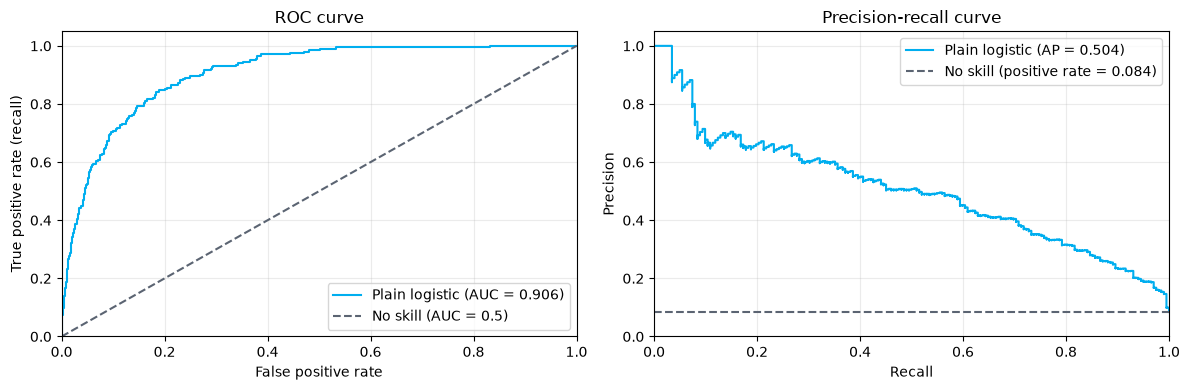

In [48]:
# Predictting the probability of the positive class.
proba_val = logreg_plain.predict_proba(Xc_val)[:, 1]

# Calculatting performance scores and the no-skill PR baseline.
roc_auc = roc_auc_score(yc_val, proba_val)
pr_auc = average_precision_score(yc_val, proba_val)
positive_rate = yc_val.mean()

# Random ranking has an expected ROC-AUC of 0.50, hence we hardcode this no-skill baseline.
print(f"ROC-AUC: {roc_auc:.3f} | No-skill ROC-AUC: 0.500")
print(
    f"PR-AUC (average precision): {pr_auc:.3f} | "
    f"No-skill PR baseline: {positive_rate:.3f}"
)

# Calculate the points for both curves.
fpr, tpr, _ = roc_curve(yc_val, proba_val)
precision, recall, _ = precision_recall_curve(yc_val, proba_val)

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 4))

# Plot the ROC curve and its no-skill baseline.
ax_roc.plot(
    fpr, tpr, color=UOW["cyan"],
    label=f"Plain logistic (AUC = {roc_auc:.3f})"
)
ax_roc.plot(
    [0, 1], [0, 1], "--", color=UOW["slate"],
    label="No skill (AUC = 0.5)"
)
ax_roc.set(
    xlabel="False positive rate",
    ylabel="True positive rate (recall)",
    title="ROC curve"
)

# Plotting the precision-recall curve and its no-skill baseline.
ax_pr.step(
    recall, precision, where="post", color=UOW["cyan"],
    label=f"Plain logistic (AP = {pr_auc:.3f})"
)
ax_pr.axhline(
    positive_rate, linestyle="--", color=UOW["slate"],
    label=f"No skill (positive rate = {positive_rate:.3f})"
)
ax_pr.set(
    xlabel="Recall",
    ylabel="Precision",
    title="Precision-recall curve"
)

# Applying the same limits and legend settings to both plots.
for ax in (ax_roc, ax_pr):
    ax.set(xlim=(0, 1), ylim=(0, 1.05))
    ax.legend()

plt.tight_layout()
plt.show()

In [49]:
# ===== SELF-CHECK 2.2 =====
assert roc_auc is not None and pr_auc is not None, "Compute both metrics."
assert roc_auc > pr_auc, "With a rare positive class ROC-AUC flatters the model relative to PR-AUC."
assert pr_auc > yc_val.mean(), "PR-AUC should beat the no-skill level, which is the positive rate."
print(f"Self-check 2.2 passed: ROC-AUC {roc_auc:.3f} vs PR-AUC {pr_auc:.3f} (no-skill {yc_val.mean():.3f}).")

Self-check 2.2 passed: ROC-AUC 0.906 vs PR-AUC 0.504 (no-skill 0.084).


### Task 2.3 — Class weights against resampling *(10 marks)*

Fit two more models on the training rows and compare all three on validation in `results_imbalance`
(accuracy, precision, recall, `n_pred_positive` and PR-AUC):

* `logreg_weighted` — `LogisticRegression(class_weight="balanced")`
* `logreg_smote` — an **`imblearn`** pipeline: `StandardScaler` → `SMOTE(random_state=RANDOM_STATE)` → `LogisticRegression`

The sampler must sit **inside** the pipeline so that it only ever sees training rows; the validation set must
keep its real 8% positive rate.

When you read the table, look at the **PR-AUC column and the recall column separately**, and ask whether the
PR-AUC differences are large enough to mean anything on ~200 validation positives. Question 2.5 asks about
this.

In [50]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# 1. Class-weighted logistic regression.
logreg_weighted = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE
    )),
])
logreg_weighted.fit(Xc_train, yc_train)

# 2. SMOTE: scale first, then resample training data.
logreg_smote = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    )),
])
logreg_smote.fit(Xc_train, yc_train)

# 3. Compare all three models on the original validation data.
models = {
    "plain": logreg_plain,
    "class_weight": logreg_weighted,
    "smote": logreg_smote,
}

scores = {}

for name, model in models.items():
    scores[name] = clf_scores(model, Xc_val, yc_val)

    # Average precision uses probabilities rather than predicted labels.
    proba = model.predict_proba(Xc_val)[:, 1]
    scores[name]["PR_AUC"] = average_precision_score(yc_val, proba)

results_imbalance = pd.DataFrame.from_dict(scores, orient="index")
results_imbalance.index.name = "model"

results_imbalance

,accuracy,precision,recall,n_pred_positive,PR_AUC
model,,,,,
plain,0.925000,0.657143,0.227723,70,0.504179
class_weight,0.803750,0.278418,0.836634,607,0.496186
smote,0.817917,0.294939,0.836634,573,0.493222


In [51]:
# ===== SELF-CHECK 2.3 =====
assert results_imbalance is not None and len(results_imbalance) == 3, "Three rows, please."
assert results_imbalance.loc["class_weight", "recall"] > results_imbalance.loc["plain", "recall"], \
    "Class weighting should raise recall at the default 0.5 threshold."
assert results_imbalance.loc["class_weight", "n_pred_positive"] > results_imbalance.loc["plain", "n_pred_positive"], \
    "...by flagging more cases."
print("Self-check 2.3 passed.")

Self-check 2.3 passed.


### Task 2.4 — Choosing the operating threshold *(8 marks)*

The business rule: **a missed positive costs 10 units, a false alarm costs 1 unit.**

Pick the model to take forward by this rule: **take the best PR-AUC, unless the models are within 0.02 of each
other, in which case prefer the simplest one** (plain < class weighting < SMOTE) and say why in 2.5. A
difference in the third decimal on ~200 positives is not evidence.

Using validation probabilities from the model you chose:

1. sweep the thresholds from the precision–recall curve and compute the expected cost
   $10 \times FN + 1 \times FP$ at each;
2. store the cost-minimising threshold in `chosen_threshold`;
3. print the confusion matrix and the classification report at that threshold, and compare the cost there with the cost at the default 0.5.

In [52]:
def print_confusion_matrix(title,data):
    print("\n",title)
    test_cm_df = pd.DataFrame(
        data,
        index=["Negative (0)", "Positive (1)"],
        columns=["Negative (0)", "Positive (1)"]
    )

    test_cm_df.index.name = "Actual class"
    test_cm_df.columns.name = "Predicted class"

    display(test_cm_df)

Selected model: plain
         threshold   FN   FP    cost
setting                             
default     0.5000  156   24  1584.0
chosen      0.0924   32  402   722.0

 Validation confusion matrix:


Predicted class,Negative (0),Positive (1)
Actual class,,
Negative (0),1796,402
Positive (1),32,170



Validation classification report:
              precision    recall  f1-score   support

           0      0.982     0.817     0.892      2198
           1      0.297     0.842     0.439       202

    accuracy                          0.819      2400
   macro avg      0.640     0.829     0.666      2400
weighted avg      0.925     0.819     0.854      2400



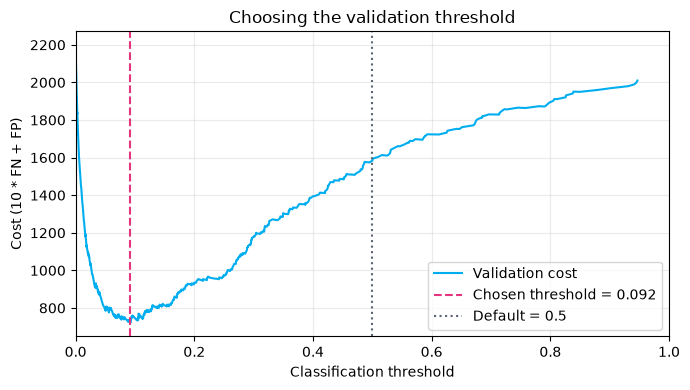

In [53]:
C_FN, C_FP = 10.0, 1.0
PR_AUC_TOLERANCE = 0.02
DEFAULT_THRESHOLD = 0.5

# Choosing the simplest model within 0.02 of the best PR-AUC.
simplicity_order = ["plain", "class_weight", "smote"]
best_pr_auc = results_imbalance["PR_AUC"].max()

best_clf_name = next(
    name for name in simplicity_order
    if best_pr_auc - results_imbalance.loc[name, "PR_AUC"]
    <= PR_AUC_TOLERANCE
)

best_clf = models[best_clf_name]
proba_val = best_clf.predict_proba(Xc_val)[:, 1]

# Including the default threshold so its cost can also be compared.
_, _, pr_thresholds = precision_recall_curve(yc_val, proba_val)
thresholds = np.unique(np.append(pr_thresholds, DEFAULT_THRESHOLD))

# Calculating and store the confusion matrix for each threshold.
confusion_matrices = np.asarray([
    confusion_matrix(
        yc_val,
        (proba_val >= threshold).astype(int),
        labels=[0, 1]
    )
    for threshold in thresholds
])

# Extracting false positives and false negatives to calculate costs.
false_positives = confusion_matrices[:, 0, 1]
false_negatives = confusion_matrices[:, 1, 0]
costs = C_FN * false_negatives + C_FP * false_positives

# Selecting the first minimum, preserving the original tie-breaking behaviour.
chosen_index = np.argmin(costs)
chosen_threshold = float(thresholds[chosen_index])
default_index = np.flatnonzero(thresholds == DEFAULT_THRESHOLD)[0]

# Comparring the default and chosen thresholds using the stored results.
comparison = pd.DataFrame([
    {
        "setting": label,
        "threshold": float(thresholds[index]),
        "FN": false_negatives[index],
        "FP": false_positives[index],
        "cost": costs[index],
    }
    for label, index in [
        ("default", default_index),
        ("chosen", chosen_index),
    ]
]).set_index("setting")

print(f"Selected model: {best_clf_name}")
print(comparison.round(4))

# Reportting performance at the chosen threshold.
chosen_predictions = (proba_val >= chosen_threshold).astype(int)

print_confusion_matrix("Validation confusion matrix:", confusion_matrices[chosen_index])

print("\nValidation classification report:")
print(
    classification_report(
        yc_val, chosen_predictions, digits=3, zero_division=0
    )
)

# Plotting validation cost against the classification threshold.
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    thresholds, costs,
    color=UOW["cyan"],
    label="Validation cost"
)
ax.axvline(
    chosen_threshold, color=UOW["pink"], linestyle="--",
    label=f"Chosen threshold = {chosen_threshold:.3f}"
)
ax.axvline(
    DEFAULT_THRESHOLD, color=UOW["slate"], linestyle=":",
    label=f"Default = {DEFAULT_THRESHOLD}"
)
ax.set(
    xlabel="Classification threshold",
    ylabel=f"Cost ({C_FN:g} * FN + {C_FP:g} * FP)"
        if C_FP != 1 else f"Cost ({C_FN:g} * FN + FP)",
    title="Choosing the validation threshold",
    xlim=(0, 1)
)
ax.legend()
plt.tight_layout()
plt.show()

In [54]:
# ===== SELF-CHECK 2.4 =====
assert chosen_threshold is not None and 0 < chosen_threshold < 1, "A probability threshold lies in (0, 1)."
assert best_clf_name is not None, "Record which model you took forward in `best_clf_name`."
assert results_imbalance["PR_AUC"].max() - results_imbalance.loc[best_clf_name, "PR_AUC"] <= 0.02, \
    "The model you took forward is clearly worse than the best one — re-read the selection rule."
_p = best_clf.predict_proba(Xc_val)[:, 1]
_tn, _fp, _fn, _tp = confusion_matrix(yc_val, (_p >= chosen_threshold).astype(int)).ravel()
_tn0, _fp0, _fn0, _tp0 = confusion_matrix(yc_val, (_p >= 0.5).astype(int)).ravel()
assert 10 * _fn + _fp <= 10 * _fn0 + _fp0, "Your threshold should not be worse than the default on cost."
print(f"Self-check 2.4 passed: cost {10 * _fn + _fp:.0f} at t={chosen_threshold:.2f} "
      f"versus {10 * _fn0 + _fp0:.0f} at t=0.5.")

Self-check 2.4 passed: cost 722 at t=0.09 versus 1584 at t=0.5.


### Final check — the test set, used once *(part of Task 2.4)*

Refit your chosen model on **train + validation**, then evaluate once on the test set at `chosen_threshold`.

In [55]:
from sklearn.base import clone
# Combining training and validation data for the final fit.
Xc_train_val = np.concatenate([Xc_train, Xc_val], axis=0)
yc_train_val = np.concatenate([yc_train, yc_val])

# Fitting a fresh copy of the selected pipeline.
final_model = clone(best_clf)
final_model.fit(Xc_train_val, yc_train_val)

# Keeping the threshold selected using validation data.
proba_test = final_model.predict_proba(Xc_test)[:, 1]
predictions_test = (proba_test >= chosen_threshold).astype(int)

# Calculating the confusion matrix and misclassification cost.
test_cm = confusion_matrix(yc_test, predictions_test, labels=[0, 1])
_, fp, fn, _ = test_cm.ravel()
test_cost = C_FN * fn + C_FP * fp

# Summarising performance on the held-out test data.
test_report = {
    "PR_AUC": average_precision_score(yc_test, proba_test),
    "ROC_AUC": roc_auc_score(yc_test, proba_test),
    "precision": precision_score(
        yc_test, predictions_test, zero_division=0
    ),
    "recall": recall_score(
        yc_test, predictions_test, zero_division=0
    ),
    "cost": test_cost,
    "threshold": chosen_threshold,
}

print_confusion_matrix("Test confusion matrix:",test_cm)

print("Final test evaluation results:")
print(pd.Series(test_report).round(4).to_string())



 Test confusion matrix:


Predicted class,Negative (0),Positive (1)
Actual class,,
Negative (0),1821,377
Positive (1),35,167


Final test evaluation results:
PR_AUC         0.5403
ROC_AUC        0.9014
precision      0.3070
recall         0.8267
cost         727.0000
threshold      0.0924


#### ✏️ Written answer 2.5 *(8 marks)* — replace this text

Answer all four, quoting your own numbers:

1. The dummy classifier's accuracy is higher than you might expect. Give its accuracy and recall, and explain in one sentence why accuracy is the wrong headline metric here.

**Mohammed Grech**:
The dummy classifier achieved 91.58% accuracy and zero recall by predicting every case as negative. Accuracy is an unsuitable headline metric because the large negative majority lets the mode achieve high accuracy while missing every positive case, even though missed positives carrying the greater cost.

2. Your ROC-AUC and PR-AUC differ substantially. Explain why, and say which you would put in a report for a manager.

**Mohammed Grech**:
Plain model validation ROC-AUC was 0.906, PR-AUC (average precision) was 0.504 (well above the no-skill PR baseline of 0.084). The ROC metric uses the false positive rate (calculated over all actual negatives). In a dataset with lots of negatives, a low false positive rate may still correspond to a lot of false alarms. Precision measures the proportion of positive predictions that are correct, making the impact of false alarms more visible. For reporting purposes, PR-AUC should be prioritised, along with recall and operating cost.

3. Class weighting and SMOTE: what did each change, and what did neither change? Are the PR-AUC differences in `results_imbalance` big enough to choose between the three models, on ~200 validation positives? Which did you take forward, and why?

**Mohammed Grech**:
Class weighting increased the underrepresented class’s contribution to the training loss, whereas SMOTE generated synthetic training examples for the minority class. At threshold 0.5, both increased recall from 0.228 to 0.837, although precision fell from 0.657 to 0.278 and 0.295, respectively. Both retained logistic regression, and validation prevalence remained 8.4%. 

Neither method improved observed PR-AUC compared with plain logistic regression. Plain scored 0.504, weighting 0.496 and SMOTE 0.493. These small differences on 202 validation positives do not establish a reliable advantage. 

The plain logistic regression was chosen since it had the highest PR-AUC, was the simplest, and all scores were within the specified 0.02 tolerance.

4. Justify your threshold in terms of the 10:1 cost. How would it move if false alarms became much more expensive, and what would you monitor after deployment?

**Mohammed Grech**:
A threshold of approximately 0.0924 was selected by minimising 10FN + FP on the validation set, where FN represents false negatives, and FP represents false positives. Compared with the default threshold of 0.5, missed positives fell from 156 to 32, while false alarms rose from 24 to 402, reducing the total cost from 1,584 to 722. This trade-off reflects the stated 10:1 cost ratio, which assigns greater importance to avoiding missed positives. Using the same threshold, the final test cost was 727. A higher cost for false alarms would generally favour a higher threshold.

After deployment, precision, recall, false-alarm volume, realised cost, positive prevalence, probability calibration, and input-data drift should be monitored. These measures help assess whether the model continues to detect positives reliably, provides trustworthy probability estimates, and maintains acceptable false-alarm levels and costs as the data and prevalence of positive cases change.

---
# Q3 — Commentary and reflection  *(20 marks)*

#### ✏️ Written answer — replace this text

Write **400–500 words**, using the headings below.

**Approach (5 marks).** The decisions you made across Q1 and Q2 and why: basis functions and prior in Q1,
the choice of λ, the metric and threshold in Q2.

**Mohammed Grech**:
Following the prescribed basis comparisons, validation RMSE was used to select a polynomial degree that captured curvature while limiting overfitting. The Gaussian prior shrank coefficients towards zero, stabilising higher-degree polynomial fits, with prior strength linked to regularisation through λ = σ²/τ². For regression with multiple features, the regularisation strength was selected using validation RMSE to balance data fit with coefficient shrinkage. Scaling made features comparable under regularisation, while keeping preprocessing within pipelines prevented data leakage.

For classification, PR-AUC and recall were prioritised when interpreting the required metrics because positive cases were rare and accuracy could conceal missed cases. The provided simplicity rule was applied to favour the simplest model when PR-AUC scores were close. Threshold selection followed the stated cost measure, accepting more false alarms to reduce the substantially more costly missed positives.

**Key results (5 marks).** Your headline numbers, each against its baseline: regression RMSE against the dummy,
PR-AUC against the positive rate, cost at your threshold against cost at 0.5.

**Mohammed Grech**:
For many-feature regression, Lasso achieved the lowest validation RMSE of 20.200, compared with 142.257 for the dummy regressor and 27.163 for ordinary least squares. It retained 10 of 60 features, recovering all eight informative features.

For classification, plain logistic regression achieved validation PR-AUC 0.504, compared with the positive-rate baseline of 0.084.

Lowering the threshold from 0.5 to approximately 0.0924 reduced validation cost from 1584 to 722. Missed positives fell from 156 to 32, while false alarms increased from 24 to 402. After refitting on training plus validation data, the final test cost was 727, with recall 0.827 and precision 0.307.

Below is a summary of the Key Results:
| Measure | Selected result | Baseline/comparison |
|---|---:|---:|
| Regression RMSE | Lasso: **20.200** | Dummy: 142.257; OLS: 27.163 |
| Classification PR-AUC | Plain logistic regression: **0.504** | Positive-rate baseline: 0.084 |
| Misclassification cost | **722** at threshold ≈ 0.0924 | 1584 at threshold 0.5 |
| Missed positives | **32** at the chosen threshold | 156 at threshold 0.5 |
| False alarms | **402** at the chosen threshold | 24 at threshold 0.5 |


| Threshold | PR-AUC | Precision | Recall | Cost |
|---:|---:|---:|---:|---:|
| ≈ 0.0924 | 0.5403 | 0.3070 | 0.8267 | 727 |

**Limitations (5 marks).** What this analysis does **not** establish. At least one point must concern the data
being synthetic and drawn from a known generative process, and one the single train/validation split.

**Mohammed Grech**:
The datasets were synthetic, so the findings may not generalise to real-world data, where noise, missing values, and underlying relationships may differ.

Results also depended on how the stratified 60/20/20 split was constructed. Reserving test data first produced different scores from reserving training data first, despite identical proportions and the same random seed. Maintaining class balance therefore does not eliminate sample-allocation variability, which may affect regularisation strength, model ranking, and threshold selection.

With only 202 validation positives, small PR-AUC differences require further uncertainty analysis before concluding that one method is better. The selected threshold reflects the assumed 10:1 cost ratio and observed positive prevalence, and may need adjustment if either changes. Probability calibration was not assessed, leaving the reliability of predicted probabilities uncertain.

**Next step (5 marks).** The one change you would make first with another week, and what you expect it to buy
you. Be specific — "use cross-validation" earns little without saying what it would change about your
conclusions.

**Mohammed Grech**:
A priority for future work would be repeated stratified nested cross-validation on the classification development data. Inner splits would select the model and decision threshold, while outer folds would evaluate PR-AUC and cost. Scaling would be fitted, and SMOTE applied only within the training folds. Tracking how often plain logistic regression remained the preferred model, alongside variation in thresholds and costs, would help assess the stability of the findings and quantify uncertainty. The existing test set would remain excluded from further tuning, and fresh held-out data would be needed for a future final evaluation.

#### Declaration of generative AI use

State which tools you used, for what, and how you verified the output. Write "None" if you used none.

I used ChatGPT and Codex to clarify workshop requirements, explain mathematical notation, debug code, and suggest reusable functions. 

I also consulted Google Search and YouTube for additional explanations.

---
## Before you submit

Run `Kernel ▸ Restart & Run All`, check that every cell executes and every plot appears, then run the cell below.

In [56]:
# ===== SUBMISSION CHECK =====
checks = {
    "Q1.1 estimators implemented": callable(fit_mle) and callable(fit_map),
    "Q1.2 prior table": prior_table is not None,
    "Q1.3 polynomial table": poly_table is not None,
    "Q1.4 model comparison": results_many is not None,
    "Q2.1 baseline table": results_baseline is not None,
    "Q2.2 both AUCs": roc_auc is not None and pr_auc is not None,
    "Q2.3 imbalance table": results_imbalance is not None,
    "Q2.4 threshold chosen": chosen_threshold is not None,
    "Q2.4 test evaluated once": test_report is not None,
}
for k, v in checks.items():
    print(("PASS  " if v else "TODO  ") + k)
print("\nRemember: the written answers carry 36 of the 100 marks (1.2, 1.5, 2.5 and Q3).")

PASS  Q1.1 estimators implemented
PASS  Q1.2 prior table
PASS  Q1.3 polynomial table
PASS  Q1.4 model comparison
PASS  Q2.1 baseline table
PASS  Q2.2 both AUCs
PASS  Q2.3 imbalance table
PASS  Q2.4 threshold chosen
PASS  Q2.4 test evaluated once

Remember: the written answers carry 36 of the 100 marks (1.2, 1.5, 2.5 and Q3).


**References**:

Matplotlib Development Team (2026) Getting started. Matplotlib documentation. Available at: https://matplotlib.org/stable/users/getting_started/ (Accessed: 25 October 2026).